In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import os
import pickle



In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

In [3]:
# Load Customer Data

file_path = r"C:\Users\Dell\Desktop\Analytics Platform\customer_analytics.csv"

customer_df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", customer_df.shape)

customer_df.head()

Dataset loaded successfully!
Shape: (102, 6)


,Customer ID,Number of Orders,Total Quantity,Total Spending,Average Order Value,Average Rating
0,CUST1069,4,133,2153701.47,5.384254e+05,3.529412
1,CUST1064,1,45,1979255.66,1.979256e+06,4.066667
2,CUST1097,3,103,1833870.66,6.112902e+05,2.838710
3,CUST1070,2,38,1781780.36,8.908902e+05,3.357143
4,CUST1041,1,16,856174.32,8.561743e+05,3.250000


In [4]:
## Inspect the Data Set

print("Columns:")
print(customer_df.columns.tolist())

print("\nData Types:")
print(customer_df.dtypes)

print("\nMissing Values:")
print(customer_df.isnull().sum())

print("\nDuplicate Rows:")
print(customer_df.duplicated().sum())

Columns:
['Customer ID', 'Number of Orders', 'Total Quantity', 'Total Spending', 'Average Order Value', 'Average Rating']

Data Types:
Customer ID             object
Number of Orders         int64
Total Quantity           int64
Total Spending         float64
Average Order Value    float64
Average Rating         float64
dtype: object

Missing Values:
Customer ID            0
Number of Orders       0
Total Quantity         0
Total Spending         0
Average Order Value    0
Average Rating         0
dtype: int64

Duplicate Rows:
0


In [5]:
## Check Statstics

customer_df.describe()

,Number of Orders,Total Quantity,Total Spending,Average Order Value,Average Rating
count,102.00000,102.000000,1.020000e+02,1.020000e+02,102.000000
mean,2.45098,56.107843,2.080975e+05,1.019493e+05,3.378191
std,1.24779,37.589999,3.907168e+05,2.428421e+05,0.334933
min,1.00000,4.000000,3.775360e+03,3.775360e+03,2.333333
25%,2.00000,25.250000,4.096890e+04,1.862150e+04,3.200000
50%,2.00000,51.500000,7.234005e+04,3.325695e+04,3.400000
75%,3.00000,78.250000,1.847045e+05,6.494967e+04,3.560764
max,7.00000,167.000000,2.153701e+06,1.979256e+06,4.625000


In [6]:
## Select feature for K-Mean

features = [
    "Number of Orders",
    "Total Quantity",
    "Total Spending",
    "Average Rating",
    "Average Order Value"
]

X = customer_df[features].copy()

print("Features selected for customer segmentation:")
print(X.columns.tolist())

print("\nShape:", X.shape)

Features selected for customer segmentation:
['Number of Orders', 'Total Quantity', 'Total Spending', 'Average Rating', 'Average Order Value']

Shape: (102, 5)


In [7]:
## check for missing ana infinite value

print("Missing values:")
print(X.isnull().sum())

print("\nInfinite values:")
print(np.isinf(X).sum())

Missing values:
Number of Orders       0
Total Quantity         0
Total Spending         0
Average Rating         0
Average Order Value    0
dtype: int64

Infinite values:
Number of Orders       0
Total Quantity         0
Total Spending         0
Average Rating         0
Average Order Value    0
dtype: int64


In [8]:
## standardize the feature

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed.
Scaled data shape: (102, 5)


In [9]:
## Test different values of K


k_values = range(2, 9)

silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

results = pd.DataFrame({
    "K": list(k_values),
    "Silhouette Score": silhouette_scores
})

results

,K,Silhouette Score
0,2,0.621121
1,3,0.329438
2,4,0.336691
3,5,0.338195
4,6,0.326574
5,7,0.337210
6,8,0.263719


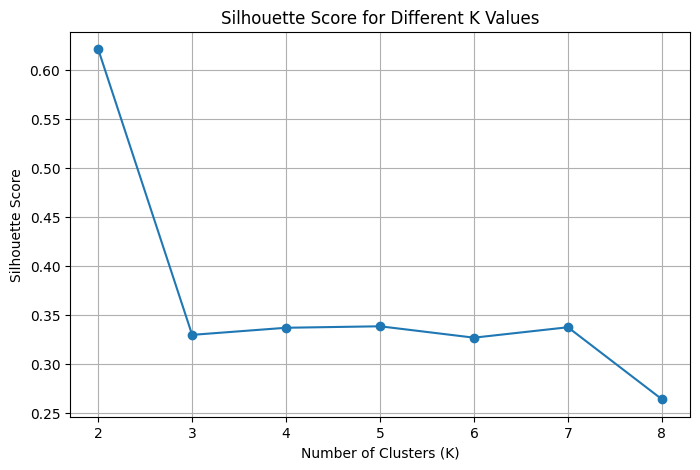

In [10]:
# Plot Silhouette Scores

plt.figure(figsize=(8, 5))

plt.plot(
    results["K"],
    results["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [11]:
# Automatically select the best K

best_k = results.loc[
    results["Silhouette Score"].idxmax(),
    "K"
]

best_score = results.loc[
    results["Silhouette Score"].idxmax(),
    "Silhouette Score"
]

print("Best K:", int(best_k))
print("Best Silhouette Score:", round(best_score, 4))

Best K: 2
Best Silhouette Score: 0.6211


In [12]:
# Train the final K-Means Model

final_kmeans = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10
)

customer_df["Segment"] = final_kmeans.fit_predict(X_scaled)

print("Final K-Means model trained successfully.")

customer_df.head()

Final K-Means model trained successfully.


,Customer ID,Number of Orders,Total Quantity,Total Spending,Average Order Value,Average Rating,Segment
0,CUST1069,4,133,2153701.47,5.384254e+05,3.529412,1
1,CUST1064,1,45,1979255.66,1.979256e+06,4.066667,1
2,CUST1097,3,103,1833870.66,6.112902e+05,2.838710,1
3,CUST1070,2,38,1781780.36,8.908902e+05,3.357143,1
4,CUST1041,1,16,856174.32,8.561743e+05,3.250000,1


In [13]:
# Analyze the customer Segments

segment_summary = customer_df.groupby("Segment").agg({
    "Customer ID": "count",
    "Number of Orders": "mean",
    "Total Quantity": "mean",
    "Total Spending": "mean",
    "Average Rating": "mean",
    "Average Order Value": "mean"
}).round(2)

segment_summary = segment_summary.rename(
    columns={"Customer ID": "Number of Customers"}
)

segment_summary

,Number of Customers,Number of Orders,Total Quantity,Total Spending,Average Rating,Average Order Value
Segment,,,,,,
0,97,2.46,55.55,130115.05,3.38,56936.01
1,5,2.20,67.00,1720956.49,3.41,975207.15


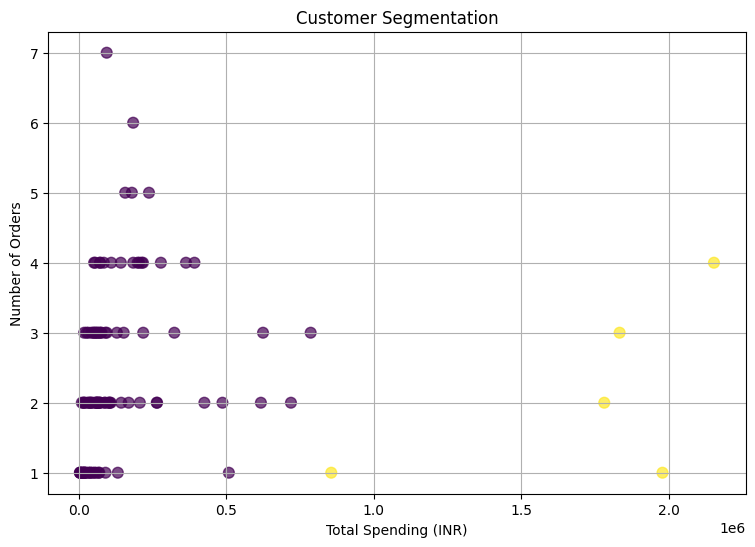

In [14]:
# Visualize the customer Segments

plt.figure(figsize=(9, 6))

plt.scatter(
    customer_df["Total Spending"],
    customer_df["Number of Orders"],
    c=customer_df["Segment"],
    s=60,
    alpha=0.7
)

plt.title("Customer Segmentation")
plt.xlabel("Total Spending (INR)")
plt.ylabel("Number of Orders")
plt.grid(True)

plt.show()

In [15]:
# Count Customers in each segment

segment_counts = customer_df["Segment"].value_counts().sort_index()

print("Customers in each segment:")
print(segment_counts)

Customers in each segment:
Segment
0    97
1     5
Name: count, dtype: int64


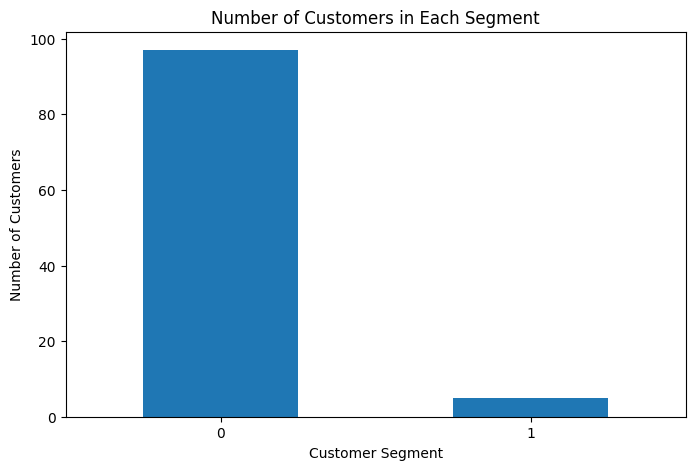

In [16]:
plt.figure(figsize=(8, 5))

segment_counts.plot(kind="bar")

plt.title("Number of Customers in Each Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()

In [17]:
# Save the customer segmentation Dataset

output_path = r"C:\Users\Dell\Desktop\Analytics Platform\customer_segments.csv"

customer_df.to_csv(
    output_path,
    index=False
)

print("Customer segmentation dataset saved successfully!")
print(output_path)

Customer segmentation dataset saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\customer_segments.csv


In [18]:
# Save the Scaler and K-Means Model

os.makedirs(r"C:\Users\Dell\Desktop\Analytics Platform", exist_ok=True)

model_data = {
    "model": final_kmeans,
    "scaler": scaler,
    "features": features,
    "best_k": int(best_k)
}

model_path = r"C:\Users\Dell\Desktop\Analytics Platform\customer_segments.pkl"


with open(model_path, "wb") as file:
    pickle.dump(model_data, file)

print("Customer segmentation model saved successfully!")
print(model_path)

Customer segmentation model saved successfully!
C:\Users\Dell\Desktop\Analytics Platform\customer_segments.pkl


In [19]:
# Verify the save file


print("customer_segments.csv exists:",
      os.path.exists( r"C:\Users\Dell\Desktop\Analytics Platform\customer_segments.csv"))

print("customer_segmentation.pkl exists:",
      os.path.exists( r"C:\Users\Dell\Desktop\Analytics Platform\customer_segments.pkl"))



customer_segments.csv exists: True
customer_segmentation.pkl exists: True
